# Shaping the invariant measure of an interconnect loop

This notebook applies **Algorithm 2** (projected subgradient) for Shaping of invariant measure

In [1]:
import os, sys
ROOT = os.path.abspath("../..")
for p in [ROOT, os.getcwd()]:
    if p not in sys.path:
        sys.path.insert(0, p)

import numpy as np
import torch
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats

from ims_core import proj_Ar, simplex_grid, projected_subgradient
from shaping_system import ShapingSim, empirical_measure
from regions import lipschitz_constants

BLUE, ORANGE, AQUA, INK, MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b", "#52514e"
SEQ = LinearSegmentedColormap.from_list("seq", ["#cde2fb", "#5598e7", "#184f95", "#0d366b"])
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": MUTED,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e1", "grid.linewidth": 0.8, "axes.titlesize": 11, "font.size": 10,
                     "lines.linewidth": 2})

## 1. The loop

`r → A1 → C → P1 → F → A1`, with the toolkit's `Aggregator`, `Controller`, `Population` and `Filter` nodes. The state $x_t\in[0,1]$ is the agent's answer, the output of `P1`. `ControlSystem.run()` keeps every node's output until the next pass, so `A1` always reads the previous answer. With $e=r-x$, $u=e$ and $r=0.5$,

$$x_{t+1}=w_i(x_t)=\mathrm{clamp}(c_i+g_i\,u_t,\,0,\,1),\qquad i\sim\mu.$$

The agent has three modes:

- **low** ($c=0.38$, $g=-0.7$) and **high** ($c=0.62$, $g=-0.7$) are contractions with slope $0.7$ that pull $x$ towards $0.1$ and $0.9$.
- **herding** ($c=0.5$, $g=-1.6$) amplifies the deviation from $r=0.5$ with slope $1.6$, so it is deliberately **not** a contraction.

The Lipschitz constants $L_i$ come from the toolkit's `get_jacobian_norm`: autograd through one pass of the loop from a state $x$, with the agent forced to mode $i$ (`ShapingSim.derivatives`). The cell after the graph also checks, step by step, that the running graph follows the maps $w_i$.

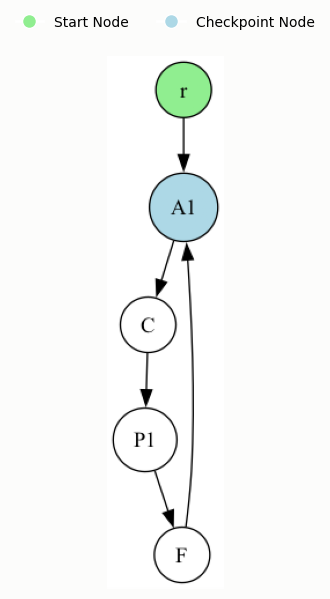

In [2]:
sim = ShapingSim()
sim.plot.render_graph()

Lipschitz constants L_i: {'low': 0.7, 'high': 0.7, 'herding': 1.6}
A_r with r=0.95: herding probability limited to 0.278
max |x_(t+1) - w_i(x_t)| over 3000 graph steps: 0.00e+00


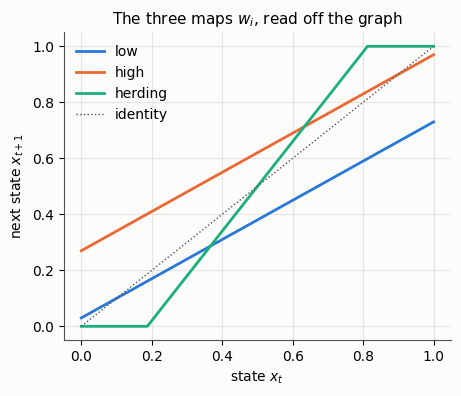

In [3]:
chain = sim.grid_chain(n=801)
x = chain.x
names = sim.mode_names

ell = lipschitz_constants(sim.derivatives(x))
r = 0.95
print("Lipschitz constants L_i:", dict(zip(names, np.round(ell, 3))))
print(f"A_r with r={r}: herding probability limited to {(r - ell[0]) / (ell[2] - ell[0]):.3f}")

# Does the real graph follow the extracted maps, step by step?
path, modes = sim.simulate([0.4, 0.4, 0.2], 3000, x0=0.0, seed=1)
pred = np.array([float(sim.one_pass(torch.tensor([xi], dtype=torch.float64), int(i))) for i, xi in zip(modes, path[:-1])])
map_error = np.abs(pred - path[1:]).max()
print(f"max |x_(t+1) - w_i(x_t)| over 3000 graph steps: {map_error:.2e}")
assert map_error < 1e-12

w = sim.maps(x)
fig, ax = plt.subplots(figsize=(5, 4))
for wi, name, c in zip(w, names, [BLUE, ORANGE, AQUA]):
    ax.plot(x, wi, color=c, label=name)
ax.plot(x, x, color=MUTED, lw=1, ls=":", label="identity")
ax.set(xlabel="state $x_t$", ylabel="next state $x_{t+1}$", title="The three maps $w_i$, read off the graph")
ax.legend(frameon=False)
plt.show()

## 2. Is the gradient right?

Algorithm 2 relies on the sensitivity formula $g_i=((w_i)_\#\pi_\mu)(u)$, with $u$ solving a Poisson equation. We compare it with central finite differences of $J$ on this system.

In [4]:
mu = np.array([0.5, 0.3, 0.2])
nu = chain.stationary(np.array([0.2, 0.6, 0.2]))
p = chain.stationary(mu)
g = chain.sensitivity(mu, p, chain.potential(p, nu))
worst = 0.0
for d in [np.array([1., -1, 0]), np.array([1., 0, -1]), np.array([0., 1, -1])]:
    fd = (chain.w1(chain.stationary(mu + 1e-4 * d), nu) - chain.w1(chain.stationary(mu - 1e-4 * d), nu)) / 2e-4
    worst = max(worst, abs(fd - g @ d))
    print(f"direction {d}: finite difference {fd:+.5f}, formula {g @ d:+.5f}")
assert worst < 1e-4

direction [ 1. -1.  0.]: finite difference +1.36262, formula +1.36262
direction [ 1.  0. -1.]: finite difference +0.26198, formula +0.26198
direction [ 0.  1. -1.]: finite difference -1.10065, formula -1.10065


## 3. Experiment A: a target the loop can reach

We plant a law $\mu^\star$, take $\nu=\pi_{\mu^\star}$ as the target, hide $\mu^\star$ and start from the projected uniform law. Theorem 6.12(b) predicts linear convergence with Polyak steps near a realizable, sharp target. Diminishing steps are shown for comparison.

In [5]:
mu_star = np.array([0.55, 0.25, 0.20])
assert ell @ mu_star <= r
nu_A = chain.stationary(mu_star)
mu0 = proj_Ar(np.ones(3) / 3, ell, r)

res_polyak = projected_subgradient(chain, nu_A, mu0, 200, step="polyak", ell=ell, r=r)
print("planted mu* :", mu_star)
print("start mu0   :", np.round(mu0, 4), f" J = {res_polyak['J'][0]:.4f}")
print("Polyak      :", np.round(res_polyak["best_mu"], 6), f" J = {res_polyak['best_J']:.2e}")

planted mu* : [0.55 0.25 0.2 ]
start mu0   : [0.3611 0.3611 0.2778]  J = 0.2084
Polyak      : [0.55 0.25 0.2 ]  J = 1.97e-14


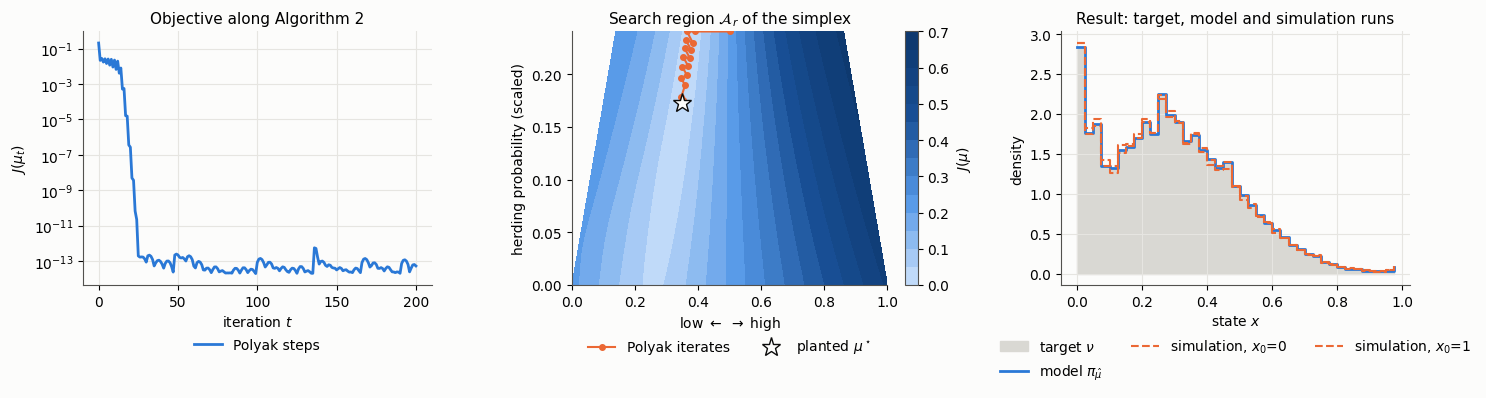

W1(simulation from x0=0, target) = 0.0011
W1(simulation from x0=1, target) = 0.0033
W1(simulation from x0=0, from x0=1) = 0.0030


In [6]:
def to_xy(m):
    m = np.atleast_2d(m)
    return m[:, 1] + 0.5 * m[:, 2], np.sqrt(3) / 2 * m[:, 2]

def bins(p, width=20):
    # mass per coarse bin as a density, so that curves on the 801-node grid are readable
    k = len(p) // width
    q = np.add.reduceat(p, np.arange(0, width * k, width))
    edges = x[np.arange(0, width * k, width)]
    return edges, q / (edges[1] - edges[0])

def plot_measures(ax, target, mu_hat, x0s=(0.0, 1.0), steps=60000, seed=3, burn=500):
    # Runs the real graph under mu_hat and overlays it on the model and the target.
    edges, d = bins(target); ax.fill_between(edges, d, step="post", color="#d9d8d3", label="target $\\nu$")
    edges, d = bins(chain.stationary(mu_hat)); ax.step(edges, d, where="post", color=BLUE, label="model $\\pi_{\\hat\\mu}$")
    emps = []
    for k, x0 in enumerate(x0s):
        path, _ = sim.simulate(mu_hat, steps, x0=x0, seed=seed + k)
        emps.append(empirical_measure(path[burn:], x))
        edges, d = bins(emps[-1]);
        ax.step(edges, d, where="post", color=ORANGE, lw=1.5, ls="--", label=f"simulation, $x_0$={x0:g}")
    ax.set(xlabel="state $x$", ylabel="density"); ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.16))
    return emps

G = simplex_grid(3, 60); G = G[G @ ell <= r + 1e-12]
top = (r - ell[0]) / (ell[2] - ell[0])   # add the edge of A_r, which is not on the grid
G = np.vstack([G, [[t * (1 - top), (1 - t) * (1 - top), top] for t in np.linspace(0, 1, 40)]])
vals_A = np.array([chain.w1(chain.stationary(m), nu_A) for m in G])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
ax = axes[0]
ax.semilogy(res_polyak["J"], color=BLUE, label="Polyak steps")
ax.set(xlabel="iteration $t$", ylabel="$J(\\mu_t)$", title="Objective along Algorithm 2"); ax.legend(frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.16))

ax = axes[1]
gx, gy = to_xy(G)
tc = ax.tricontourf(mtri.Triangulation(gx, gy), vals_A, levels=14, cmap=SEQ)
fig.colorbar(tc, ax=ax, label="$J(\\mu)$", fraction=0.046)
tx, ty = to_xy(res_polyak["traj"]); ax.plot(tx, ty, color=ORANGE, marker="o", ms=4, lw=1.5, label="Polyak iterates")
sx, sy = to_xy(mu_star); ax.plot(sx, sy, "*", color="#fcfcfb", mec=INK, ms=14, label="planted $\\mu^\\star$")
ax.set(xlabel="low $\\leftarrow$ $\\to$ high", ylabel="herding probability (scaled)", title="Search region $\\mathcal{A}_r$ of the simplex")
ax.grid(False); ax.legend(frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.16))

ax = axes[2]
emps_A = plot_measures(ax, nu_A, res_polyak["best_mu"]); ax.set_title("Result: target, model and simulation runs")
fig.tight_layout(); plt.show()

print(f"W1(simulation from x0=0, target) = {chain.w1(emps_A[0], nu_A):.4f}")
print(f"W1(simulation from x0=1, target) = {chain.w1(emps_A[1], nu_A):.4f}")
print(f"W1(simulation from x0=0, from x0=1) = {chain.w1(emps_A[0], emps_A[1]):.4f}")

## 4. Experiment B: a target the loop cannot reach exactly


Now $\nu=\mathrm{Beta}(14,6)$, a law the three modes cannot produce exactly, so the best $J$ is above zero. We run Algorithm 2 from three starts and use a fine grid search over $\mathcal A_r$ as an independent reference. $J$ is not convex, so agreement with the grid is the evidence that the point found is a good one.

grid search (2450 evaluations): mu = [0.25 0.75 0.  ],  J = 0.04063


Algorithm 2 from [0.33 0.33 0.33]: mu = [0.2462 0.7538 0.    ],  J = 0.04057


Algorithm 2 from [0.05 0.9  0.05]: mu = [0.2462 0.7538 0.    ],  J = 0.04057


Algorithm 2 from [0.5 0.3 0.2]: mu = [0.2462 0.7538 0.    ],  J = 0.04057


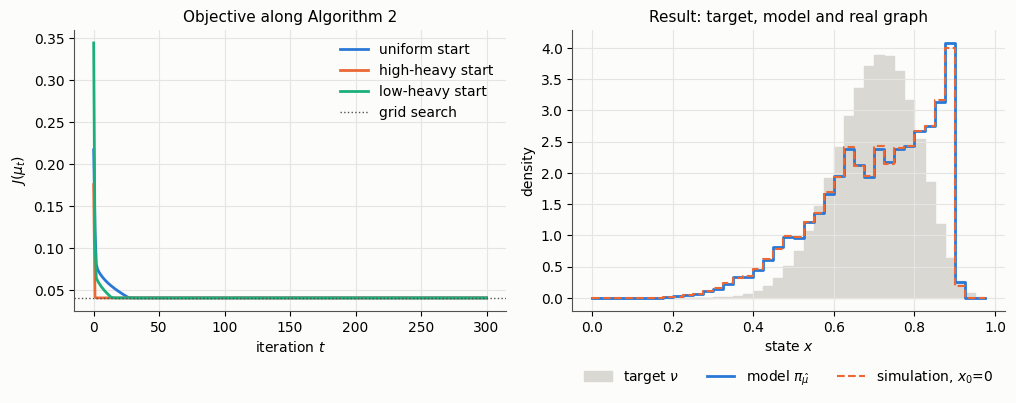

mean: target 0.700, achieved 0.703
sd  : target 0.100, achieved 0.145


In [7]:
def beta_target(comps):
    e = np.concatenate([[0], (x[:-1] + x[1:]) / 2, [1]])
    p = sum(w * np.diff(stats.beta(a, b).cdf(e)) for w, a, b in comps)
    return p / p.sum()


# Algorithm 1 baseline
nu_B = beta_target([(1, 14, 6)])
G_fine = simplex_grid(3, 100); G_fine = G_fine[G_fine @ ell <= r + 1e-12]
vals_B = np.array([chain.w1(chain.stationary(m), nu_B) for m in G_fine])
mu_grid = G_fine[np.argmin(vals_B)]
print(f"grid search ({len(G_fine)} evaluations): mu = {mu_grid},  J = {vals_B.min():.5f}")

runs_B = []
for s in [np.ones(3) / 3, np.array([0.05, 0.9, 0.05]), np.array([0.5, 0.3, 0.2])]:
    res = projected_subgradient(chain, nu_B, proj_Ar(s, ell, r), 300, gamma=0.3, ell=ell, r=r)
    runs_B.append(res)
    print(f"Algorithm 2 from {s.round(2)}: mu = {np.round(res['best_mu'], 4)},  J = {res['best_J']:.5f}")
    assert res["best_J"] <= vals_B.min() + 1e-3
best_B = min(runs_B, key=lambda res: res["best_J"])

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2))
for res, c, lab in zip(runs_B, [BLUE, ORANGE, AQUA], ["uniform start", "high-heavy start", "low-heavy start"]):
    axes[0].plot(res["J"], color=c, label=lab)
axes[0].axhline(vals_B.min(), color=MUTED, lw=1, ls=":", label="grid search")
axes[0].set(xlabel="iteration $t$", ylabel="$J(\\mu_t)$", title="Objective along Algorithm 2"); axes[0].legend(frameon=False)
emps_B = plot_measures(axes[1], nu_B, best_B["best_mu"], [0.0]); axes[1].set_title("Result: target, model and real graph")
fig.tight_layout(); plt.show()

pi_B = chain.stationary(best_B["best_mu"])
print(f"mean: target {x @ nu_B:.3f}, achieved {x @ pi_B:.3f}")
print(f"sd  : target {np.sqrt(((x - x @ nu_B)**2) @ nu_B):.3f}, achieved {np.sqrt(((x - x @ pi_B)**2) @ pi_B):.3f}")